# Staircase pilot: what is the smallest phase shift I can detect?

This notebook reads the output of `run_staircase_speech.py` / `run_staircase_acoustic.py` for **one participant**
and estimates the detection threshold **T**: the phase-shift size (ms) at which the irregular presentation is
picked correctly **79.4 %** of the time in the 2IFC task (the target of the 3-down-1-up rule).

T comes out two ways:

| Estimate | What it is | When to trust it |
|---|---|---|
| **Reversal threshold** (the planned rule) | geometric mean of each staircase's reversal sizes after the first `N_DISCARD` (3) | needs at least 2 reversals left after the discard |
| **Psychometric fit** | a Weibull function fitted to *all* trials of a direction (maximum likelihood); T = size at 79.4 % correct | uses every trial, so it still works on short runs |

Steps:
1. Settings
2. Load the files and combine the sessions (a crash / restart gives several files)
3. Quality checks: the staircase rule, the stimuli, the timing
4. Staircase tracks
5. Reversal thresholds
6. Psychometric function
7. Other effects: interval, sentence type, presentation order (bias), block, reaction times
8. Practice trials
9. Summary and the jitter sizes for detection and tapping

Run the cells from top to bottom. Change only the **Settings** cell.

## 1 Settings
`DATA_DIR` is the folder with the `staircase_*.tsv` files (`DATA_DIR` in `staircase_params.py`: `data`
on the lab computer, `data_test` on the laptop). Figures and a summary CSV go to `DATA_DIR/analysis_<pid>_<group>/`.

In [1]:
import os
from pathlib import Path

DATA_DIR    = Path(os.environ.get('STAIR_DATA_DIR',
                   '/Users/bastugb/Desktop/tapping_detection_sentences/staircase_pilot/data_test'))
PARTICIPANT = 'P02'
GROUP       = 'acoustic'          # 'speech' / 'acoustic'
EXCLUDE_SESSIONS = []             # session_time strings to ignore, e.g. ['20261120_102426']

# staircase settings: must match staircase_params.py
START_MS, GRID_FACTOR, MIN_MS = 90.0, 1.2, 3.0
N_DOWN, N_UP = 3, 1
BIG_STEP, SMALL_STEP, SWITCH_AFTER = 2, 1, 2
N_DISCARD = 3                     # reversals dropped before averaging

# analysis settings
TARGET_P   = 0.794                # 3-down-1-up converges here
LAPSE_MAX  = 0.06                 # the fitted lapse rate may go up to 6 %
N_BOOT     = 1000                 # bootstrap samples for the confidence intervals of the fit
SEED       = 1
ROUND_TO_MS, JITTER_CAP_MS = 5, 80   # decision rule: T rounded to 5 ms; sizes 0.5T, T, 2T, at most 80 ms
SAVE_FIGS  = True

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
from scipy.optimize import minimize
from scipy.stats import norm

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

LEVELS = [round(START_MS / GRID_FACTOR ** k, 2)
          for k in range(int(np.floor(np.log(START_MS / MIN_MS) / np.log(GRID_FACTOR))) + 1)]
STAIRCASES = ['delay_1', 'delay_2', 'advance_1', 'advance_2']
DIRECTIONS = ['delay', 'advance']

# colours: one hue per direction (delay = blue, advance = orange), copy 1 solid / copy 2 dashed
COL = {'delay': '#2a78d6', 'advance': '#eb6834', 'pooled': '#3d3d3a'}
LS = {1: '-', 2: '--'}
MUTED = '#8a8980'

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': '#3d3d3a', 'xtick.color': '#5f5e58', 'ytick.color': '#5f5e58',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'legend.frameon': False, 'lines.linewidth': 2,
})

OUT_DIR = DATA_DIR / f'analysis_{PARTICIPANT}_{GROUP}'
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    if SAVE_FIGS:
        fig.savefig(OUT_DIR / f'{name}.png')

def size_axis(ax, which='y', lo=None, hi=100):
    """Log axis for shift sizes, ticks on every 3rd grid size (90, 52, 30, 17, 10, 6, 3.4)."""
    lo_ = lo or LEVELS[-1] / 1.1
    ticks = LEVELS if hi / lo_ < GRID_FACTOR ** 10 else LEVELS[::3]   # all grid sizes when the range is narrow
    ticks = [t for t in ticks if lo_ <= t <= hi]
    if which == 'y':
        ax.set_yscale('log'); ax.yaxis.set_major_locator(FixedLocator(ticks))
        ax.yaxis.set_major_formatter(FixedFormatter([f'{t:g}' for t in ticks])); ax.yaxis.set_minor_locator(NullLocator())
        ax.set_ylim(lo or LEVELS[-1] / 1.1, hi)
    else:
        ax.set_xscale('log'); ax.xaxis.set_major_locator(FixedLocator(ticks))
        ax.xaxis.set_major_formatter(FixedFormatter([f'{t:g}' for t in ticks])); ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xlim(lo or LEVELS[-1] / 1.1, hi)

def geo_mean(x):
    x = np.asarray(x, float)
    return float(np.exp(np.log(x).mean())) if x.size else np.nan

print('size grid:', LEVELS)

size grid: [90.0, 75.0, 62.5, 52.08, 43.4, 36.17, 30.14, 25.12, 20.93, 17.44, 14.54, 12.11, 10.09, 8.41, 7.01, 5.84, 4.87, 4.06, 3.38]


## 2 Load the files and combine the sessions
Every run of the experiment writes its own files (`staircase_…tsv`, `practice_…tsv`, `thresholds_…csv`), named by
the session start time. If you quit and restarted, there are several. They are combined the same way the
experiment resumes: sessions are sorted by time and, for every trial number, the row of the **latest** session is
kept. A restart at block 1 therefore replaces the earlier attempt completely. Sessions listed in
`EXCLUDE_SESSIONS` are left out.

In [3]:
def read_all(kind, sep='\t', ext='tsv'):
    files = sorted(DATA_DIR.glob(f'{kind}_{PARTICIPANT}_{GROUP}_*.{ext}'))
    parts = []
    for f in files:
        d = pd.read_csv(f, sep=sep, dtype={'session_time': str})
        d['file'] = f.name
        d['session_time'] = f.stem.split('_', 3)[-1]
        parts.append(d)
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

raw = read_all('staircase')
if raw.empty:
    raise FileNotFoundError(f'no staircase_{PARTICIPANT}_{GROUP}_*.tsv in {DATA_DIR}')

overview = (raw.groupby('session_time')
               .agg(file=('file', 'first'), n_trials=('trial', 'size'), first_trial=('trial', 'min'),
                    last_trial=('trial', 'max'), blocks=('block', lambda b: ','.join(map(str, sorted(b.unique())))))
               .reset_index())
overview['excluded'] = overview['session_time'].isin(EXCLUDE_SESSIONS)
display(overview)

use = raw[~raw['session_time'].isin(EXCLUDE_SESSIONS)].sort_values(['session_time', 'trial'])
df = use.drop_duplicates('trial', keep='last').sort_values('trial').reset_index(drop=True)

df['correct'] = df['correct'].astype(int)
df['no_response'] = df['response'].astype(str).eq('none')
df['size_ms'] = df['size_ms'].astype(float)
df['copy'] = df['copy'].astype(int)
df['interval'] = pd.Categorical(df['interval'], ['I1', 'I2', 'I3', 'I4', 'I5'], ordered=True)

print(f"\nAnalysed: {len(df)} trials (blocks {sorted(df['block'].unique())}), "
      f"taken from sessions {df.groupby('session_time').size().to_dict()}")
print(f"No response (counted as wrong): {df['no_response'].sum()}")
print(f"Overall accuracy: {df['correct'].mean():.1%}")
display(df.groupby('staircase').agg(n_trials=('trial', 'size'), accuracy=('correct', 'mean'),
                                    last_size_ms=('sc_next_size_ms', 'last')).reindex(STAIRCASES))

,session_time,file,n_trials,first_trial,last_trial,blocks,excluded
0,20261120_102426,staircase_P02_acoustic_20261120_102426.tsv,7,1,7,1,False
1,20261120_103221,staircase_P02_acoustic_20261120_103221.tsv,90,1,90,"1,2",False
2,20261121_120134,staircase_P02_acoustic_20261121_120134.tsv,90,91,180,"3,4",False



Analysed: 180 trials (blocks [1, 2, 3, 4]), taken from sessions {'20261120_103221': 90, '20261121_120134': 90}
No response (counted as wrong): 0
Overall accuracy: 83.9%


,n_trials,accuracy,last_size_ms
staircase,,,
delay_1,45,0.866667,43.40
delay_2,45,0.822222,62.50
advance_1,45,0.822222,43.40
advance_2,45,0.844444,52.08


## 3 Quality checks
Three checks before trusting any number:

* **Staircase rule.** The 3-down-1-up rule is run again on the logged answers (same rule and step sizes as
  PsychoPy's `StairHandler`). The sizes it gives must match the sizes that were played. This also shows that
  combining the sessions did not break a staircase.
* **Stimuli.** Word-list trials should contain word lists, not sentences. (Before 20 Nov the word-list slot used
  copies of the 3|3 sentences as a placeholder.)
* **Timing.** Sound onset vs the scheduled onset, the "2" label vs the start of presentation 2, and the time per
  trial (to project the full 180-trial session).

In [5]:
def replay_staircase(correct_seq):
    """3-down-1-up exactly like psychopy.data.StairHandler (stepType 'log', applyInitialRule False)."""
    g = np.log10(GRID_FACTOR)
    steps = [BIG_STEP * g] * SWITCH_AFTER + [SMALL_STEP * g]
    x, counter, direction, step = START_MS, 0, 'start', steps[0]
    sizes, rev_flags, revs = [], [], []
    for c in correct_seq:
        sizes.append(x)
        if c: counter = counter + 1 if counter >= 0 else 1
        else: counter = counter - 1 if counter <= 0 else -1
        rev = False
        if counter >= N_DOWN:
            rev, direction = direction not in ('start', 'down'), 'down'
        elif counter <= -N_UP:
            rev, direction = direction not in ('start', 'up'), 'up'
        if rev:
            revs.append(x); step = steps[min(len(revs), len(steps) - 1)]
        if counter >= N_DOWN:
            x, counter = max(x / 10 ** step, LEVELS[-1]), 0
        elif counter <= -N_UP:
            x, counter = min(x * 10 ** step, START_MS), 0
        rev_flags.append(rev)
    return np.array(sizes), np.array(rev_flags), revs

problems = []
for sc in STAIRCASES:
    d = df[df['staircase'] == sc].sort_values('trial')
    if not (d['staircase_trial'].to_numpy() == np.arange(1, len(d) + 1)).all():
        problems.append(f'{sc}: staircase_trial is not 1..n (trials missing?)')
    sizes, revs, _ = replay_staircase(d['correct'].to_numpy())
    if not np.allclose(sizes, d['size_ms'].to_numpy(), rtol=0.01):
        k = int(np.argmax(~np.isclose(sizes, d['size_ms'].to_numpy(), rtol=0.01)))
        problems.append(f'{sc}: played size differs from the rule at staircase trial {k + 1}')
    if not (revs == d['sc_reversal'].astype(bool).to_numpy()).all():
        problems.append(f'{sc}: logged reversals differ from the rule')
print('Staircase rule:', 'OK - every played size and reversal follows 3-down-1-up' if not problems
      else '\n  ' + '\n  '.join(problems))

# placeholder word lists?
wl = df.loc[df['sentence_type'] == 'word list', 'words'].unique()
sentences = set(df.loc[df['sentence_type'] != 'word list', 'words'])
same = [w for w in wl if w in sentences]
if len(wl) and len(same) == len(wl):
    print(f'Word lists: WARNING - all {len(wl)} word-list items are sentences (placeholder). '
          'Treat "word list" as a third set of 3|3 sentences.')
elif same:
    print(f'Word lists: WARNING - {len(same)} of {len(wl)} word-list items are also sentences:', same)
else:
    print(f'Word lists: OK ({len(wl)} items, none is a sentence)')

Staircase rule: OK - every played size and reversal follows 3-down-1-up
Word lists: WARNING - all 18 word-list items are sentences (placeholder). Treat "word list" as a third set of 3|3 sentences.


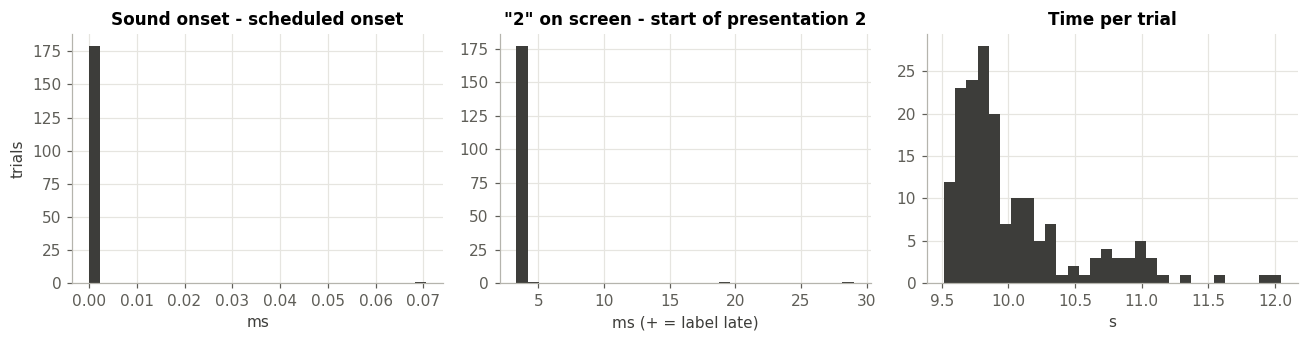

onset error: median 0.00 ms, max |err| 0.07 ms
label '2': median 3.6 ms after presentation 2 starts (range 3.3 to 29.0)
time per trial: median 9.86 s -> 180 trials = 29.6 min (without instructions, practice and breaks)


In [6]:
t = df.copy()
t['onset_err_ms'] = (t['t_onset'] - t['t_onset_scheduled']) * 1000
t['label2_err_ms'] = (t['t_label2_on'] - (t['t_onset'] + t['pres2_start_s'])) * 1000
t['trial_dur_s'] = t.groupby('block')['t_pre_sound_on'].diff().shift(-1)   # start of this trial -> start of the next

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].hist(t['onset_err_ms'], bins=30, color=COL['pooled'])
ax[0].set(title='Sound onset - scheduled onset', xlabel='ms', ylabel='trials')
ax[1].hist(t['label2_err_ms'], bins=30, color=COL['pooled'])
ax[1].set(title='"2" on screen - start of presentation 2', xlabel='ms (+ = label late)')
ax[2].hist(t['trial_dur_s'].dropna(), bins=30, color=COL['pooled'])
ax[2].set(title='Time per trial', xlabel='s')
fig.tight_layout(); save(fig, '03_timing'); plt.show()

per_trial = t['trial_dur_s'].median()
print(f"onset error: median {t['onset_err_ms'].median():.2f} ms, max |err| {t['onset_err_ms'].abs().max():.2f} ms")
print(f"label '2': median {t['label2_err_ms'].median():.1f} ms after presentation 2 starts "
      f"(range {t['label2_err_ms'].min():.1f} to {t['label2_err_ms'].max():.1f})")
print(f"time per trial: median {per_trial:.2f} s -> 180 trials = {180 * per_trial / 60:.1f} min "
      f"(without instructions, practice and breaks)")

## 4 Staircase tracks
One panel per staircase: the size played on each of its trials. **Filled** dots = correct, **open** dots = wrong,
× = no response. Ringed points are reversals; the grey ones are the first `N_DISCARD`, which are not used.
The horizontal line is the staircase's reversal threshold (section 5), if it has one.
A good track goes down quickly and then moves up and down around one level.

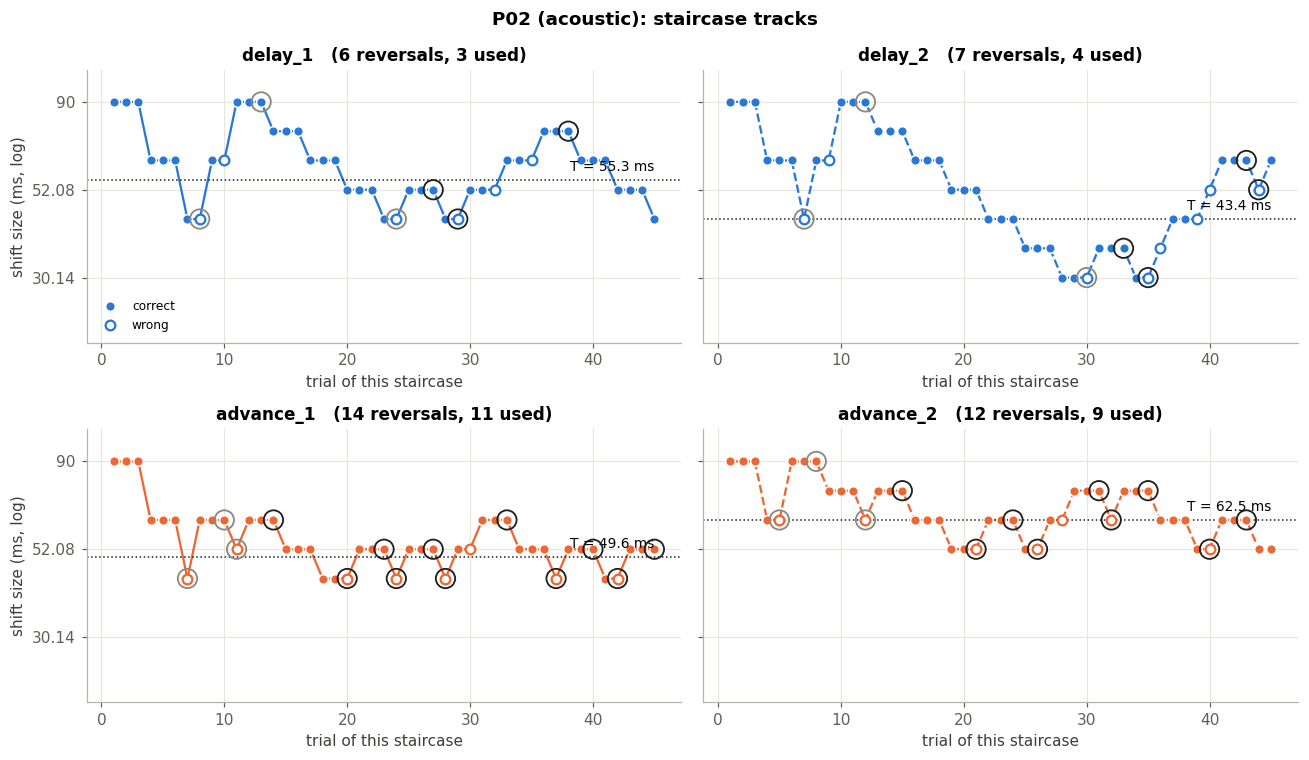

In [7]:
def rev_threshold(d):
    r = d.loc[d['sc_reversal'].astype(bool), 'size_ms'].to_numpy()
    return geo_mean(r[N_DISCARD:]), r

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, sc in zip(axes.ravel(), STAIRCASES):
    d = df[df['staircase'] == sc].sort_values('trial')
    direction, copy = sc.split('_')
    c = COL[direction]
    x = d['staircase_trial'].to_numpy(); y = d['size_ms'].to_numpy()
    ax.plot(x, y, color=c, lw=1.5, ls=LS[int(copy)], zorder=1)
    ok = d['correct'].to_numpy() == 1; nr = d['no_response'].to_numpy()
    ax.scatter(x[ok], y[ok], s=40, color=c, edgecolor='white', linewidth=1, zorder=3, label='correct')
    ax.scatter(x[~ok & ~nr], y[~ok & ~nr], s=40, facecolor='white', edgecolor=c, linewidth=1.5, zorder=3, label='wrong')
    if nr.any():
        ax.scatter(x[nr], y[nr], s=50, marker='x', color=c, zorder=3, label='no response')
    rv = d['sc_reversal'].astype(bool).to_numpy()
    for i, (xx, yy) in enumerate(zip(x[rv], y[rv])):
        ax.scatter(xx, yy, s=160, facecolor='none', edgecolor=MUTED if i < N_DISCARD else '#1f1f1d',
                   linewidth=1.2, zorder=4)
    thr, revs = rev_threshold(d)
    if np.isfinite(thr):
        ax.axhline(thr, color='#1f1f1d', lw=1, ls=':')
        ax.text(x.max(), thr * 1.04, f'T = {thr:.1f} ms', ha='right', va='bottom', fontsize=9)
    ax.set_title(f'{sc}   ({len(revs)} reversals, {max(0, len(revs) - N_DISCARD)} used)')
    ax.set_xlabel('trial of this staircase'); size_axis(ax, 'y', lo=LEVELS[-1] / 1.1)
    ax.set_ylim(max(LEVELS[-1] / 1.1, df['size_ms'].min() / 1.5), 110)
for ax in axes[:, 0]:
    ax.set_ylabel('shift size (ms, log)')
axes[0, 0].legend(loc='lower left', fontsize=8)
fig.suptitle(f'{PARTICIPANT} ({GROUP}): staircase tracks', fontweight='bold')
fig.tight_layout(); save(fig, '04_staircase_tracks'); plt.show()

All four staircases on the session's trial axis. Dotted lines are block borders. This shows whether the
staircases settle together and whether anything changes after a break.

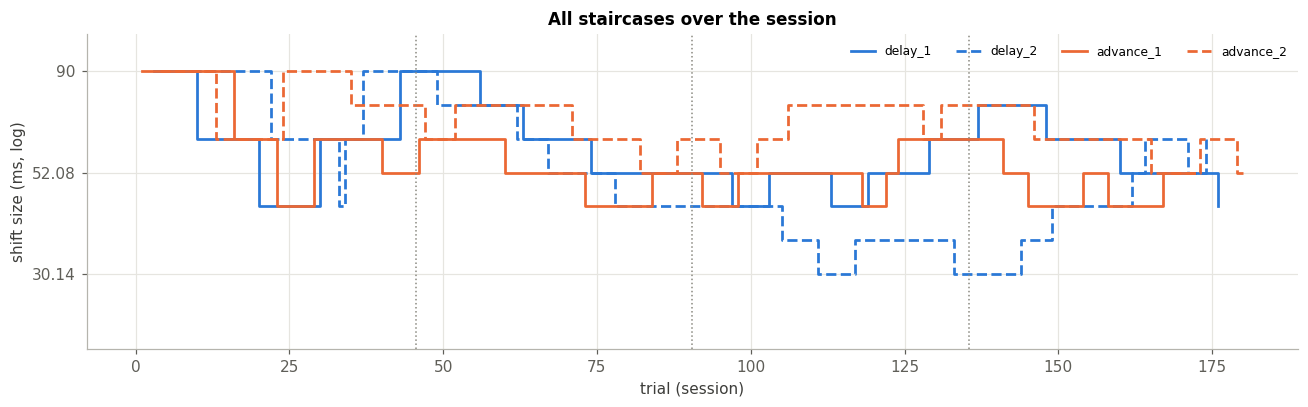

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.8))
for sc in STAIRCASES:
    d = df[df['staircase'] == sc].sort_values('trial')
    direction, copy = sc.split('_')
    ax.step(d['trial'], d['size_ms'], where='post', color=COL[direction], ls=LS[int(copy)], lw=1.8, label=sc)
for b in df.groupby('block')['trial'].min().iloc[1:]:
    ax.axvline(b - 0.5, color=MUTED, ls=':', lw=1)
size_axis(ax, 'y'); ax.set_ylim(max(LEVELS[-1] / 1.1, df['size_ms'].min() / 1.5), 110)
ax.set(xlabel='trial (session)', ylabel='shift size (ms, log)', title='All staircases over the session')
ax.legend(ncol=4, loc='upper right', fontsize=8)
fig.tight_layout(); save(fig, '04_staircases_session'); plt.show()

## 5 Reversal thresholds (the planned rule)
Per staircase: geometric mean of the reversal sizes after the first `N_DISCARD`. Per direction: geometric mean
of its two staircases. A staircase with fewer than 2 reversals left gives no or a weak estimate (flagged).
For comparison, `last10_ms` is the geometric mean of the last 10 sizes played: rougher, but it always exists.

In [9]:
rows = []
for sc in STAIRCASES:
    d = df[df['staircase'] == sc].sort_values('trial')
    thr, revs = rev_threshold(d)
    used = revs[N_DISCARD:]
    rows.append(dict(staircase=sc, direction=sc.split('_')[0], n_trials=len(d), n_reversals=len(revs),
                     n_used=len(used), reversals_ms=' '.join(f'{r:g}' for r in revs),
                     threshold_ms=thr, last10_ms=geo_mean(d['size_ms'].tail(10)),
                     note='' if len(used) >= 2 else ('no reversals left - no estimate' if not len(used)
                                                     else 'only 1 reversal - weak')))
rev_tab = pd.DataFrame(rows)
display(rev_tab.round(2))

rev_dir = rev_tab.groupby('direction')['threshold_ms'].apply(lambda s: geo_mean(s.dropna()) if s.notna().any() else np.nan)
rev_dir = rev_dir.reindex(DIRECTIONS)
print('Reversal threshold per direction (ms):', rev_dir.round(1).to_dict())

# the thresholds file written by the experiment (latest session) - should agree when only one session is used
thr_files = sorted(DATA_DIR.glob(f'thresholds_{PARTICIPANT}_{GROUP}_*.csv'))
if thr_files:
    print(f'\nthresholds file of the latest session ({thr_files[-1].name}):')
    display(pd.read_csv(thr_files[-1])[['staircase', 'n_trials', 'n_reversals', 'threshold_ms']].round(2))

,staircase,direction,n_trials,n_reversals,n_used,reversals_ms,threshold_ms,last10_ms,note
0,delay_1,delay,45,6,3,43.4 90 43.4 52.08 43.4 75,55.34,60.26,
1,delay_2,delay,45,7,4,43.4 90 30.14 36.17 30.14 62.5 52.08,43.40,51.14,
2,advance_1,advance,45,14,11,43.4 62.5 52.08 62.5 43.4 52.08 43.4 52.08 43....,49.55,49.31,
3,advance_2,advance,45,12,9,62.5 90 62.5 75 52.08 62.5 52.08 75 62.5 75 52...,62.50,58.10,


Reversal threshold per direction (ms): {'delay': 49.0, 'advance': 55.7}

thresholds file of the latest session (thresholds_P02_acoustic_20261121_120134.csv):


,staircase,n_trials,n_reversals,threshold_ms
0,delay_1,45,6,55.34
1,delay_2,45,7,43.40
2,advance_1,45,14,49.55
3,advance_2,45,12,62.50


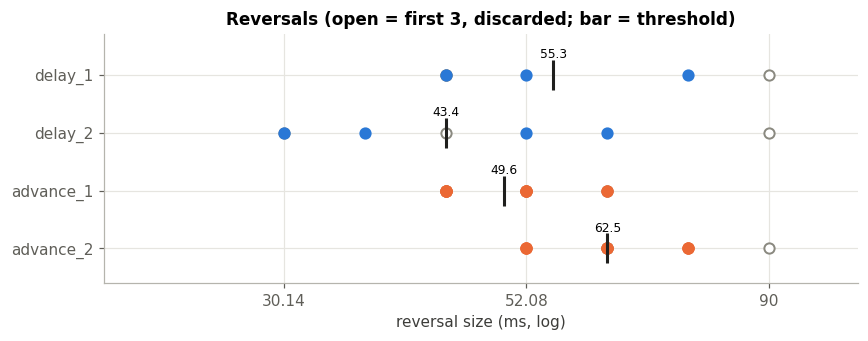

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, r in rev_tab.iterrows():
    direction = r['direction']
    revs = [float(v) for v in r['reversals_ms'].split()] if r['reversals_ms'] else []
    yy = len(STAIRCASES) - 1 - i
    for j, v in enumerate(revs):
        ax.scatter(v, yy, s=45, facecolor='white' if j < N_DISCARD else COL[direction],
                   edgecolor=MUTED if j < N_DISCARD else COL[direction], linewidth=1.3, zorder=3)
    if np.isfinite(r['threshold_ms']):
        ax.scatter(r['threshold_ms'], yy, marker='|', s=400, color='#1f1f1d', linewidth=2, zorder=4)
        ax.text(r['threshold_ms'], yy + 0.28, f"{r['threshold_ms']:.1f}", ha='center', fontsize=8)
ax.set_yticks(range(len(STAIRCASES))); ax.set_yticklabels(STAIRCASES[::-1]); ax.set_ylim(-0.6, len(STAIRCASES) - 0.3)
size_axis(ax, 'x'); ax.set_xlim(max(LEVELS[-1] / 1.1, df['size_ms'].min() / 1.5), 110)
ax.set(xlabel='reversal size (ms, log)',
       title=f'Reversals (open = first {N_DISCARD}, discarded; bar = threshold)')
fig.tight_layout(); save(fig, '05_reversals'); plt.show()

## 6 Psychometric function
All trials are grouped by size. Percent correct is plotted against size (dot area = number of trials, bars =
95 % Wilson interval). A 2IFC **Weibull** function is fitted by maximum likelihood:

$$p(x) = 0.5 + (0.5-\lambda)\,\bigl(1-e^{-(x/\alpha)^\beta}\bigr)$$

0.5 is chance, λ the lapse rate (0 to 6 %), α and β the position and slope. **T** is the size where the curve
crosses 79.4 %. The fits are done for delay, advance, and both together.

The 95 % confidence intervals come from a bootstrap (trials resampled with replacement, 1000 refits). Staircase
trials are not independent and most of them sit near threshold, so read the intervals as approximate. A
threshold outside the tested sizes (above 90 ms or below the smallest size played) is extrapolated and flagged.

In [11]:
def weibull(x, alpha, beta, lam):
    return 0.5 + (0.5 - lam) * (1 - np.exp(-(np.asarray(x, float) / alpha) ** beta))

BOUNDS = [(np.log(1), np.log(1000)), (np.log(0.5), np.log(10)), (0, LAPSE_MAX)]

def fit_weibull(x, k, n, starts=None):
    x, k, n = map(lambda v: np.asarray(v, float), (x, k, n))
    def nll(p):
        pr = np.clip(weibull(x, np.exp(p[0]), np.exp(p[1]), p[2]), 1e-9, 1 - 1e-9)
        return -np.sum(k * np.log(pr) + (n - k) * np.log(1 - pr))
    starts = starts or [(np.log(a), np.log(b), 0.02) for a in (10, 25, 50, 80) for b in (1.5, 3)]
    best = min((minimize(nll, s, method='L-BFGS-B', bounds=BOUNDS) for s in starts), key=lambda r: r.fun)
    return dict(alpha=np.exp(best.x[0]), beta=np.exp(best.x[1]), lam=best.x[2], nll=best.fun, x0=tuple(best.x))

def threshold(fit, p=TARGET_P):
    q = (p - 0.5) / (0.5 - fit['lam'])
    return np.nan if q >= 1 else fit['alpha'] * (-np.log(1 - q)) ** (1 / fit['beta'])

def aggregate(d):
    return d.groupby('size_ms')['correct'].agg(k='sum', n='size').reset_index()

def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h

rng = np.random.default_rng(SEED)
subsets = {'delay': df[df['direction'] == 'delay'], 'advance': df[df['direction'] == 'advance'], 'pooled': df}
fits, agg, boot = {}, {}, {}
for name, d in subsets.items():
    a = aggregate(d); agg[name] = a
    fits[name] = f = fit_weibull(a['size_ms'], a['k'], a['n'])
    sizes, corr = d['size_ms'].to_numpy(), d['correct'].to_numpy()
    th = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(d), len(d))
        ab = pd.DataFrame({'size_ms': sizes[i], 'correct': corr[i]}).groupby('size_ms')['correct'].agg(['sum', 'size'])
        fb = fit_weibull(ab.index, ab['sum'], ab['size'], starts=[f['x0'], (np.log(30), np.log(2), 0.02)])
        th.append(threshold(fb))
    boot[name] = np.array(th)

lo_tested = df['size_ms'].min()
fit_tab = pd.DataFrame([dict(fit=name, n_trials=len(subsets[name]), alpha=f['alpha'], beta=f['beta'],
                             lapse=f['lam'], T_794_ms=threshold(f),
                             ci_low=np.nanpercentile(boot[name], 2.5), ci_high=np.nanpercentile(boot[name], 97.5),
                             T_75_ms=threshold(f, 0.75),
                             flag='extrapolated' if not lo_tested <= threshold(f) <= START_MS else '')
                        for name, f in fits.items()])
display(fit_tab.round(2))

,fit,n_trials,alpha,beta,lapse,T_794_ms,ci_low,ci_high,T_75_ms,flag
0,delay,90,52.50,3.03,0.0,50.45,35.19,59.81,46.51,
1,advance,90,56.80,5.07,0.0,55.47,46.98,61.00,52.84,
2,pooled,180,55.33,4.08,0.0,53.72,46.11,59.11,50.57,


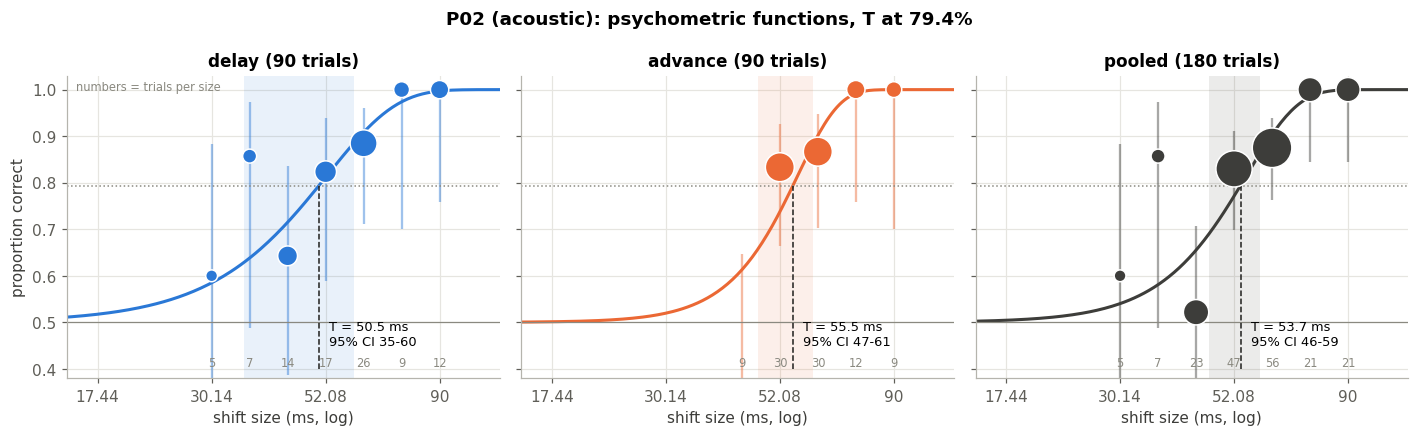

In [12]:
xs = np.geomspace(LEVELS[-1], 120, 300)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, name in zip(axes, ['delay', 'advance', 'pooled']):
    a, f, c = agg[name], fits[name], COL[name]
    lo, hi = wilson(a['k'], a['n'])
    ax.vlines(a['size_ms'], lo, hi, color=c, alpha=0.45, lw=1.5)
    ax.scatter(a['size_ms'], a['k'] / a['n'], s=12 * a['n'], color=c, edgecolor='white', linewidth=1, zorder=3)
    for _, r in a.iterrows():
        ax.text(r['size_ms'], 0.405, int(r['n']), ha='center', fontsize=7.5, color=MUTED)
    ax.plot(xs, weibull(xs, f['alpha'], f['beta'], f['lam']), color=c, lw=2)
    T = threshold(f); ci = np.nanpercentile(boot[name], [2.5, 97.5])
    ax.axhline(TARGET_P, color=MUTED, ls=':', lw=1); ax.axhline(0.5, color=MUTED, lw=0.8)
    if np.isfinite(T):
        ax.axvspan(*ci, color=c, alpha=0.10, lw=0)
        ax.plot([T, T], [0.4, TARGET_P], color='#1f1f1d', lw=1, ls='--')
        ax.text(T * 1.05, 0.45, f'T = {T:.1f} ms\n95% CI {ci[0]:.0f}-{ci[1]:.0f}', fontsize=8.5)
    size_axis(ax, 'x', lo=max(LEVELS[-1], df['size_ms'].min() / 2), hi=120)
    ax.set(title=f'{name} ({int(a["n"].sum())} trials)', xlabel='shift size (ms, log)', ylim=(0.38, 1.03))
axes[0].set_ylabel('proportion correct')
axes[0].text(0.02, 0.98, 'numbers = trials per size', transform=axes[0].transAxes, fontsize=7.5, color=MUTED, va='top')
fig.suptitle(f'{PARTICIPANT} ({GROUP}): psychometric functions, T at {TARGET_P:.1%}', fontweight='bold')
fig.tight_layout(); save(fig, '06_psychometric'); plt.show()

Both directions on one plot (does an early word or a late word need a bigger shift?), and the bootstrap
distribution of each threshold. Mostly overlapping distributions = no clear difference between the directions.

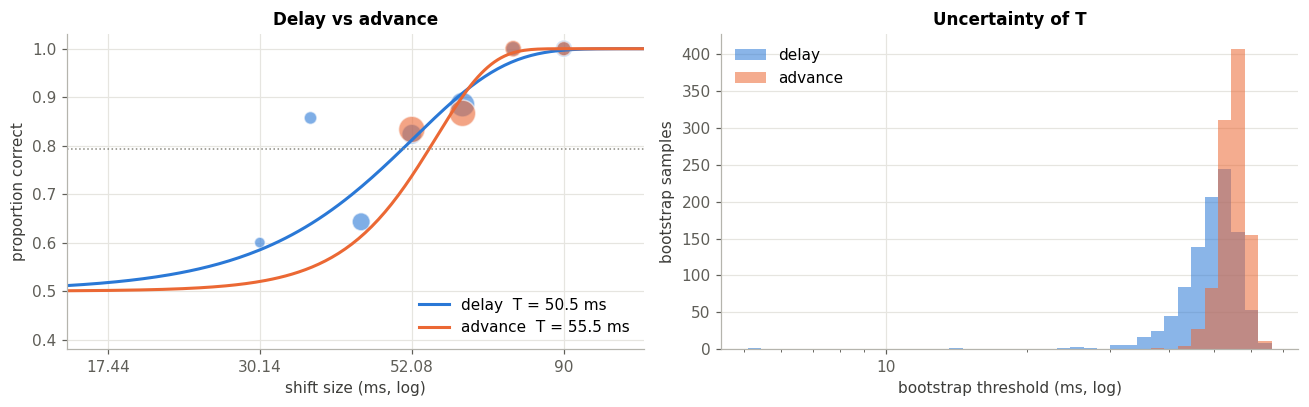

bootstrap: delay threshold > advance threshold in 22% of samples
delay / advance threshold ratio: 0.91  (plan: revisit the rule if > 2 or < 0.5 in most participants)


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name in DIRECTIONS:
    f, a = fits[name], agg[name]
    ax[0].plot(xs, weibull(xs, f['alpha'], f['beta'], f['lam']), color=COL[name], label=f'{name}  T = {threshold(f):.1f} ms')
    ax[0].scatter(a['size_ms'], a['k'] / a['n'], s=10 * a['n'], color=COL[name], alpha=0.6, edgecolor='white')
ax[0].axhline(TARGET_P, color=MUTED, ls=':', lw=1)
size_axis(ax[0], 'x', lo=max(LEVELS[-1], df['size_ms'].min() / 2), hi=120)
ax[0].set(xlabel='shift size (ms, log)', ylabel='proportion correct', ylim=(0.38, 1.03), title='Delay vs advance')
ax[0].legend(loc='lower right')

allb = np.concatenate([boot[n][np.isfinite(boot[n])] for n in DIRECTIONS])
bins = np.geomspace(max(1, allb.min()), allb.max(), 40)
for name in DIRECTIONS:
    b = boot[name][np.isfinite(boot[name])]
    ax[1].hist(b, bins=bins, color=COL[name], alpha=0.55, label=name)
ax[1].set_xscale('log'); ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
ax[1].set(xlabel='bootstrap threshold (ms, log)', ylabel='bootstrap samples', title='Uncertainty of T')
ax[1].legend()
fig.tight_layout(); save(fig, '06_delay_vs_advance'); plt.show()

ratio = threshold(fits['delay']) / threshold(fits['advance'])
p_delay_larger = np.nanmean(boot['delay'] > boot['advance'])
print(f'bootstrap: delay threshold > advance threshold in {p_delay_larger:.0%} of samples')
print(f'delay / advance threshold ratio: {ratio:.2f}  (plan: revisit the rule if > 2 or < 0.5 in most participants)')

## 7 Other effects
Raw accuracy per condition is misleading here: the staircase plays different sizes in different conditions.
So each trial is compared with what the pooled psychometric function predicts **at its own size**:
`observed - predicted`. A mean around 0 = the condition is as easy as expected; below 0 = harder; above 0 = easier.
Bars = ±1 standard error, numbers = trials. With one participant and ~90-180 trials, only large differences mean
anything.

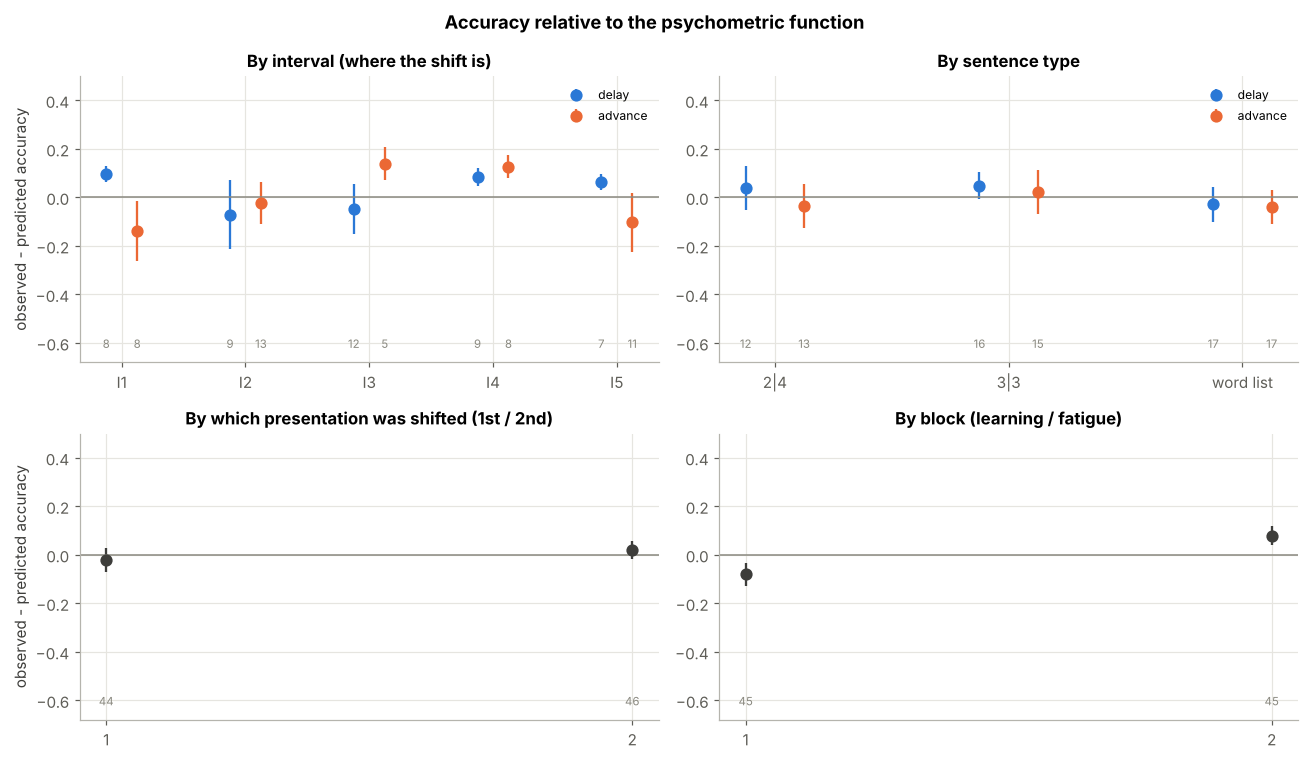

In [13]:
fp = fits['pooled']
df['p_pred'] = weibull(df['size_ms'], fp['alpha'], fp['beta'], fp['lam'])
df['resid'] = df['correct'] - df['p_pred']

def resid_plot(ax, by, title, hue=None):
    keys = [by] + ([hue] if hue else [])
    g = df.groupby(keys, observed=True)['resid'].agg(['mean', 'sem', 'size']).reset_index()
    levels = list(dict.fromkeys(g[by]))
    if hue:
        for j, h in enumerate(DIRECTIONS):
            gg = g[g[hue] == h].set_index(by).reindex(levels)
            xx = np.arange(len(levels)) + (j - 0.5) * 0.25
            ax.errorbar(xx, gg['mean'], gg['sem'], fmt='o', color=COL[h], ms=7, capsize=0, lw=1.5, label=h)
            for x_, m, n in zip(xx, gg['mean'], gg['size']):
                if np.isfinite(m):
                    ax.text(x_, -0.62, int(n), ha='center', fontsize=7.5, color=MUTED)
        ax.legend(fontsize=8, loc='upper right')
    else:
        ax.errorbar(range(len(levels)), g['mean'], g['sem'], fmt='o', color=COL['pooled'], ms=7, lw=1.5)
        for x_, n in enumerate(g['size']):
            ax.text(x_, -0.62, int(n), ha='center', fontsize=7.5, color=MUTED)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(range(len(levels))); ax.set_xticklabels([str(l) for l in levels])
    ax.set(title=title, ylim=(-0.68, 0.5))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
resid_plot(axes[0, 0], 'interval', 'By interval (where the shift is)', hue='direction')
resid_plot(axes[0, 1], 'sentence_type', 'By sentence type', hue='direction')
resid_plot(axes[1, 0], 'shifted_presentation', 'By which presentation was shifted (1st / 2nd)')
resid_plot(axes[1, 1], 'block', 'By block (learning / fatigue)')
for ax in axes[:, 0]:
    ax.set_ylabel('observed - predicted accuracy')
fig.suptitle('Accuracy relative to the psychometric function', fontweight='bold')
fig.tight_layout(); save(fig, '07_effects'); plt.show()

**Response bias.** In 2IFC a listener may lean towards answering "first" or "second". `c` is the criterion
(0 = no bias, > 0 = leans towards "second", < 0 = towards "first"), `d'` the sensitivity over all sizes.
A strong bias does not invalidate the threshold, but it is worth knowing about (e.g. the second presentation is
always compared with a fresh memory of the first).

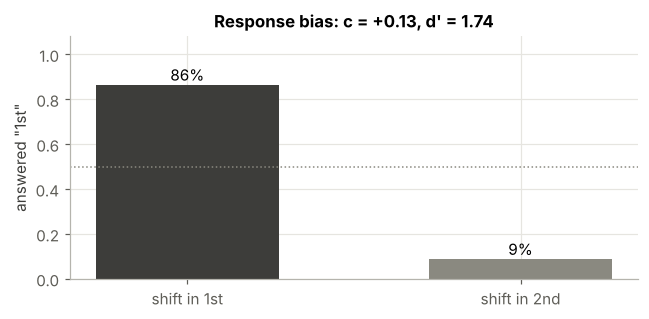

pressed "1st": 46.7% of answered trials


In [14]:
r = df[~df['no_response']]
H = ((r['response'].astype(int) == 1) & (r['shifted_presentation'] == 1)).sum() / (r['shifted_presentation'] == 1).sum()
F = ((r['response'].astype(int) == 1) & (r['shifted_presentation'] == 2)).sum() / (r['shifted_presentation'] == 2).sum()
n1, n2 = (r['shifted_presentation'] == 1).sum(), (r['shifted_presentation'] == 2).sum()
Hc, Fc = np.clip(H, 0.5 / n1, 1 - 0.5 / n1), np.clip(F, 0.5 / n2, 1 - 0.5 / n2)
dprime = (norm.ppf(Hc) - norm.ppf(Fc)) / np.sqrt(2)
crit = -(norm.ppf(Hc) + norm.ppf(Fc)) / 2

fig, ax = plt.subplots(figsize=(6, 3))
props = r.groupby('shifted_presentation')['response'].apply(lambda s: (s.astype(int) == 1).mean())
ax.bar(['shift in 1st', 'shift in 2nd'], props.values, color=[COL['pooled'], MUTED], width=0.55)
for i, v in enumerate(props.values):
    ax.text(i, v + 0.02, f'{v:.0%}', ha='center')
ax.axhline(0.5, color=MUTED, ls=':', lw=1)
ax.set(ylim=(0, 1.08), ylabel='answered "1st"', title=f"Response bias: c = {crit:+.2f}, d' = {dprime:.2f}")
fig.tight_layout(); save(fig, '07_bias'); plt.show()
print(f'pressed "1st": {(r["response"].astype(int) == 1).mean():.1%} of answered trials')

**Reaction times** (from the end of the sound; answers during the sound were not allowed). Wrong answers are
usually slower, and RTs usually rise as the size approaches threshold: a quick sign that the task was done
properly and not by guessing quickly.

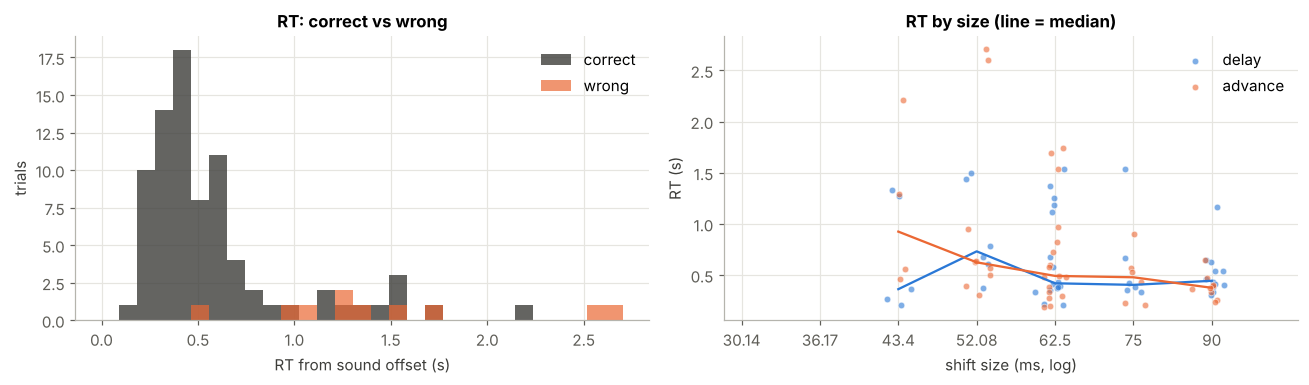

,count,mean,std,min,25%,50%,75%,max
correct,,,,,,,,
0,10.0,1.512,0.681,0.557,1.151,1.310,1.692,2.705
1,80.0,0.580,0.394,0.185,0.355,0.431,0.637,2.209


In [15]:
r = df[~df['no_response']].copy()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.linspace(0, r['rt_from_offset_s'].max(), 30)
ax[0].hist(r.loc[r['correct'] == 1, 'rt_from_offset_s'], bins=bins, color=COL['pooled'], alpha=0.8, label='correct')
ax[0].hist(r.loc[r['correct'] == 0, 'rt_from_offset_s'], bins=bins, color=COL['advance'], alpha=0.7, label='wrong')
ax[0].set(xlabel='RT from sound offset (s)', ylabel='trials', title='RT: correct vs wrong'); ax[0].legend()
for name in DIRECTIONS:
    d = r[r['direction'] == name]
    jitter = np.exp(np.random.default_rng(0).normal(0, 0.02, len(d)))
    ax[1].scatter(d['size_ms'] * jitter, d['rt_from_offset_s'], s=18, color=COL[name], alpha=0.6,
                  edgecolor='white', linewidth=0.5, label=name)
    m = d.groupby('size_ms')['rt_from_offset_s'].median()
    ax[1].plot(m.index, m.values, color=COL[name], lw=1.5)
size_axis(ax[1], 'x', lo=max(LEVELS[-1], df['size_ms'].min() / 1.5), hi=110)
ax[1].set(xlabel='shift size (ms, log)', ylabel='RT (s)', title='RT by size (line = median)'); ax[1].legend()
fig.tight_layout(); save(fig, '07_rt'); plt.show()
display(r.groupby('correct')['rt_from_offset_s'].describe().round(3))

## 8 Practice trials
Six practice trials at 90 ms with feedback (not part of the staircases). One row per practice run.

,session_time,n,correct,no_response,median_rt_s,accuracy
0,20261120_102035,6,5,0,0.431,0.833
1,20261120_102426,6,4,0,0.572,0.667
2,20261120_103221,6,2,0,0.854,0.333


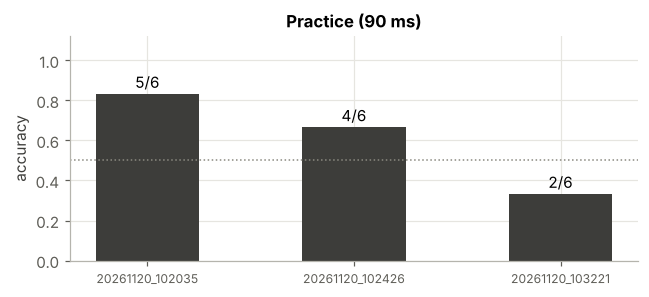

In [16]:
prac = read_all('practice')
if prac.empty:
    print('no practice files')
else:
    ps = prac.groupby('session_time').agg(n=('practice_trial', 'size'), correct=('correct', 'sum'),
                                          no_response=('response', lambda s: (s.astype(str) == 'none').sum()),
                                          median_rt_s=('rt_from_offset_s', 'median')).reset_index()
    ps['accuracy'] = ps['correct'] / ps['n']
    display(ps.round(3))
    fig, ax = plt.subplots(figsize=(6, 2.8))
    ax.bar(ps['session_time'], ps['accuracy'], color=COL['pooled'], width=0.5)
    ax.axhline(0.5, color=MUTED, ls=':', lw=1)
    for i, (a, c, n) in enumerate(zip(ps['accuracy'], ps['correct'], ps['n'])):
        ax.text(i, a + 0.03, f'{c}/{n}', ha='center')
    ax.set(ylim=(0, 1.12), ylabel='accuracy', title='Practice (90 ms)')
    ax.tick_params(axis='x', labelsize=8)
    fig.tight_layout(); save(fig, '08_practice'); plt.show()

## 9 Summary and the jitter sizes
All threshold estimates on one axis. **T for the decision** follows the plan: per direction, the reversal
threshold if both staircases of that direction give one, otherwise the psychometric fit; then the median over the
directions (with more participants: over participants and directions), rounded to 5 ms.
Jitter sizes = 0.5T, T, 2T, each rounded to 5 ms, the largest at most 80 ms.

,participant,group,direction,T_reversal_ms,T_fit_ms,fit_ci_low,fit_ci_high,T_used_ms,T_source,n_trials
0,P02,acoustic,delay,NaN,50.37,13.13,62.00,50.37,psychometric fit,45
1,P02,acoustic,advance,57.05,56.31,40.07,63.79,57.05,reversals,45
2,P02,acoustic,pooled,NaN,53.97,42.57,60.96,NaN,NaN,90


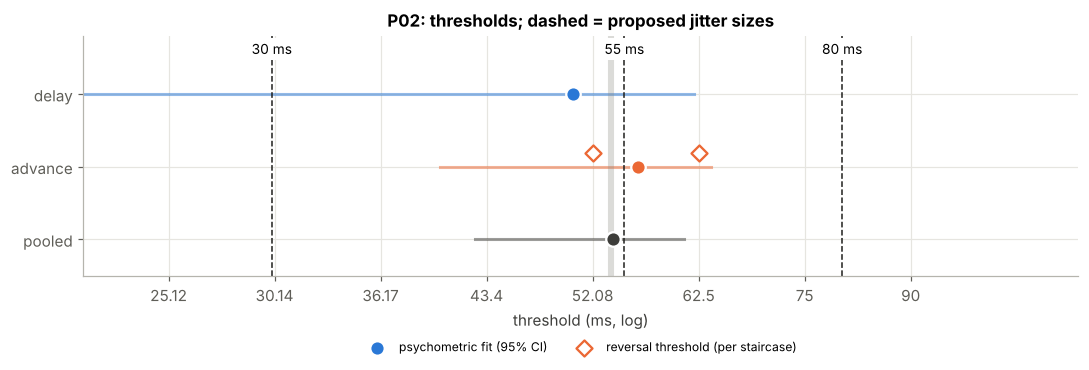

T per direction: delay 50.4 ms (psychometric fit), advance 57.1 ms (reversals)
T (median of directions) = 53.7 ms -> rounded 55 ms
Proposed JITTER_SIZES_MS = [30, 55, 80]

Figures and summary CSV in /home/claude/stair_nb/data/analysis_P02_acoustic


In [17]:
def rnd(v):
    return max(ROUND_TO_MS, ROUND_TO_MS * round(v / ROUND_TO_MS))

T_dir, source = {}, {}
for name in DIRECTIONS:
    rv = rev_tab.loc[rev_tab['direction'] == name, 'threshold_ms']
    if rv.notna().all():
        T_dir[name], source[name] = geo_mean(rv), 'reversals'
    else:
        T_dir[name], source[name] = threshold(fits[name]), 'psychometric fit'
T = float(np.median(list(T_dir.values())))
T_round = rnd(T)
jitters = sorted({min(JITTER_CAP_MS, rnd(f * T_round)) for f in (0.5, 1, 2)})

summary = pd.DataFrame([dict(participant=PARTICIPANT, group=GROUP, direction=n,
                             T_reversal_ms=rev_dir[n], T_fit_ms=threshold(fits[n]),
                             fit_ci_low=np.nanpercentile(boot[n], 2.5), fit_ci_high=np.nanpercentile(boot[n], 97.5),
                             T_used_ms=T_dir[n], T_source=source[n]) for n in DIRECTIONS]
                       + [dict(participant=PARTICIPANT, group=GROUP, direction='pooled',
                               T_fit_ms=threshold(fits['pooled']),
                               fit_ci_low=np.nanpercentile(boot['pooled'], 2.5),
                               fit_ci_high=np.nanpercentile(boot['pooled'], 97.5))])
summary['n_trials'] = [len(subsets[n]) for n in ['delay', 'advance', 'pooled']]
summary.to_csv(OUT_DIR / f'summary_{PARTICIPANT}_{GROUP}.csv', index=False)
display(summary.round(2))

fig, ax = plt.subplots(figsize=(10, 3.6))
rows_y = {'delay': 2, 'advance': 1, 'pooled': 0}
for name, yy in rows_y.items():
    c = COL[name]
    lo_, hi_ = np.nanpercentile(boot[name], [2.5, 97.5])
    ax.plot([lo_, hi_], [yy, yy], color=c, lw=2, alpha=0.5)
    ax.scatter(threshold(fits[name]), yy, s=90, color=c, edgecolor='white', linewidth=1.5, zorder=3,
               label='psychometric fit (95% CI)' if name == 'delay' else None)
    if name in DIRECTIONS:
        for k, sc in enumerate([f'{name}_1', f'{name}_2']):
            v = rev_tab.set_index('staircase').loc[sc, 'threshold_ms']
            if np.isfinite(v):
                ax.scatter(v, yy + 0.18, s=55, marker='D', facecolor='white', edgecolor=c, linewidth=1.5, zorder=3,
                           label='reversal threshold (per staircase)' if name == 'advance' and k == 0 else None)
for j in jitters:
    ax.axvline(j, color='#1f1f1d', ls='--', lw=1)
    ax.text(j, 2.55, f'{j:g} ms', ha='center', fontsize=9, bbox=dict(facecolor='white', edgecolor='none', pad=1.5))
ax.axvline(T, color=MUTED, lw=4, alpha=0.3)
ax.set_yticks(list(rows_y.values())); ax.set_yticklabels(list(rows_y.keys())); ax.set_ylim(-0.5, 2.8)
size_axis(ax, 'x', lo=max(LEVELS[-1], df['size_ms'].min() / 2), hi=120)
ax.set(xlabel='threshold (ms, log)', title=f'{PARTICIPANT}: thresholds; dashed = proposed jitter sizes')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8)
fig.tight_layout(); save(fig, '09_summary'); plt.show()

print(f"T per direction: " + ', '.join(f"{n} {T_dir[n]:.1f} ms ({source[n]})" for n in DIRECTIONS))
print(f'T (median of directions) = {T:.1f} ms -> rounded {T_round} ms')
print(f'Proposed JITTER_SIZES_MS = {jitters}')
print(f'\nFigures and summary CSV in {OUT_DIR}')

### Reading the result
* **Staircases converged?** In section 4, each track should have settled around one level. If a track is still
  going down at the end, T is overestimated: the session was too short for this listener.
* **Reversal vs fit:** both should land in the same range. If they don't, trust the fit when there are few
  reversals, and the reversals when the fit is extrapolated.
* **One pilot participant gives a first guess, not the final value.** The plan takes the median over 4-6 pilot
  participants (speech and acoustic). Paste each participant's `summary_*.csv` together and take the median of
  `T_used_ms`.